# Phase 6: Deep Learning Forecasting Models (LSTM, GRU, BiLSTM, CNN-LSTM & Hybrid)
**Course:** UCS321 – Engineering Design / EST Course Project  
**Client / Domain:** Indian Oil Corporation (Refinery Zone: CPCL Manali, Chennai)  
**Objective:** Engineer, optimize, and evaluate multivariate deep recurrent neural networks for proactive daily Air Quality Index (AQI) forecasting.

---

### Phase 6 Architecture & Methodological Blueprint
1. **Leakage-Safe Sequence Formulation:**
   - Chronological sliding windows constructed across concatenated time series.
   - Origin $t$ features: inputs over $[t - L + 1, \dots, t]$.
   - Target: $\text{AQI}(t+1)$ for 1-day ahead models; $\text{AQI}(t+1 \dots t+7)$ for direct 7-day models.
   - Partitioning by target date: windows look strictly into past observations across split boundaries without forward leakage.
   - Scalers fitted strictly on Train partition (`2016-01-01` to `2018-12-31`).

2. **Systematic 3-Stage Experimental Search:**
   - **Stage 1 (Feature Set $\times$ Lookback):** Evaluates $4$ feature representations $\times 4$ lookback horizons ($L \in \{7, 14, 30, 60\}$) across $5$ random seeds using a baseline 2-layer Stacked LSTM.
   - **Stage 2 (Architecture Tournament):** Compares Stacked LSTM, Stacked GRU, Bidirectional LSTM, and Conv1D-LSTM across top configurations (5 seeds each).
   - **Stage 3 (Optuna Bayesian Optimization):** 60-trial TPE hyperparameter optimization with median early-stopping pruning on the winning architecture family, followed by 5-seed confirmation.

3. **Advanced Production Extensions:**
   - **Ensemble & Bayesian Uncertainty:** 5-seed ensemble retraining on Train+Val with Monte Carlo (MC) Dropout (500 stochastic forward passes) generating $95\%$ predictive confidence bands.
   - **Direct 7-Day Forecasting:** Dense(7) multi-step model evaluated on identical forecast origins from Phase 5 ($N=175$ origins).
   - **Hybrid ARIMAX + LSTM:** Leakage-safe residual LSTM predicting in-sample and out-of-sample ARIMAX errors.
   - **Lockdown Stress Testing:** Generalization evaluation under the COVID-19 lockdown window (`2020-03-01` to `2020-06-30`).

In [1]:
import os
import sys

# Ensure repository root is in python path
sys.path.insert(0, os.path.abspath('..'))

import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual formatting
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Path constants
DATA_PROCESSED = '../data/processed'
FIG_DIR = '../outputs/figures'
RES_DIR = '../outputs/results'
MODELS_DIR = '../outputs/models'

for d in [FIG_DIR, RES_DIR, MODELS_DIR]:
    os.makedirs(d, exist_ok=True)

# Hardware execution report
import psutil
print("System Compute Environment:")
print(f" - Logical CPU Cores:  {psutil.cpu_count(logical=True)}")
print(f" - Physical CPU Cores: {psutil.cpu_count(logical=False)}")
print(f" - RAM Available:      {psutil.virtual_memory().total / (1024**3):.1f} GB")
print(f" - Platform:           Windows (TensorFlow 2.16 CPU execution)")

System Compute Environment:
 - Logical CPU Cores:  24
 - Physical CPU Cores: 16
 - RAM Available:      15.7 GB
 - Platform:           Windows (TensorFlow 2.16 CPU execution)


## 1. Stage 1: Feature Set $\times$ Lookback Grid Search
We analyze the performance of $16$ candidate configurations ($4$ feature sets $\times 4$ lookback horizons, $5$ seeds each = $80$ runs) evaluated on the out-of-sample Validation partition (`2019-01-01` to `2019-08-31`).

Feature representations:
- **(U) Univariate:** AQI + Day-of-Year cyclical $\sin/\cos$ ($3$ features)
- **(P) Parsimonious:** AQI + $\text{PM}_{2.5}$ + $\text{CO}$ + $\text{O}_3$ + Day-of-Year cyclical ($6$ features)
- **(C) CORE5:** AQI + $\text{PM}_{2.5}$ + $\text{CO}$ + $\text{O}_3$ + $\text{NO}_2$ + $\text{SO}_2$ + Day-of-Year cyclical ($8$ features)
- **(A) ALL9:** AQI + $9$ pollutants + Day-of-Year cyclical ($12$ features)

In [2]:
# Load experimental runs
exp_df = pd.read_csv(os.path.join(RES_DIR, 'p6_experiments.csv'))
s1_df = exp_df[exp_df['stage'] == 1].copy()

# Compute mean and std val RMSE
s1_summary = s1_df.groupby(['feature_set', 'lookback'])['val_RMSE'].agg(['mean', 'std', 'count']).reset_index()
s1_summary = s1_summary.sort_values('mean')

print("=== Stage 1: Feature Set x Lookback Validation RMSE (5 Seeds) ===")
display(s1_summary)

# Pivot table for heatmap
s1_pivot = s1_summary.pivot(index='feature_set', columns='lookback', values='mean')
s1_pivot = s1_pivot.reindex(['U', 'P', 'C', 'A'])

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(s1_pivot, annot=True, fmt='.2f', cmap='YlGnBu_r', cbar_kws={'label': 'Validation RMSE (AQI)'}, ax=ax, annot_kws={'fontweight': 'bold', 'size': 11})
ax.set_title('Stage 1 Heatmap: Validation RMSE by Feature Set & Lookback Horizon', fontsize=12, fontweight='bold')
ax.set_xlabel('Lookback Window L (Days)', fontsize=10, fontweight='bold')
ax.set_ylabel('Feature Representation', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_stage1_heatmap.png'), dpi=300)
plt.show()

# Top 2 selections
top2 = s1_summary.head(2).to_dict('records')
print(f"\nTop 2 Configurations selected for Architecture Search:")
for i, c in enumerate(top2, 1):
    print(f" {i}. Feature Set: {c['feature_set']}, Lookback: {c['lookback']} days -> Mean Val RMSE: {c['mean']:.2f} ± {c['std']:.2f}")

=== Stage 1: Feature Set x Lookback Validation RMSE (5 Seeds) ===


,feature_set,lookback,mean,std,count
4,C,7,27.3750,0.513283,5
5,C,14,27.9058,0.212804,5
7,C,60,27.9242,0.300961,5
6,C,30,27.9726,0.317604,5
9,P,14,28.1056,0.825843,5
8,P,7,28.1772,0.253162,5
0,A,7,28.1952,0.317882,5
10,P,30,28.4702,0.820779,5
11,P,60,28.4994,0.385401,5
1,A,14,28.6448,0.191749,5


<Figure size 800x600 with 2 Axes>


Top 2 Configurations selected for Architecture Search:
 1. Feature Set: C, Lookback: 7 days -> Mean Val RMSE: 27.38 ± 0.51
 2. Feature Set: C, Lookback: 14 days -> Mean Val RMSE: 27.91 ± 0.21


## 2. Stage 2: Architecture Tournament
On the top 2 feature set $\times$ lookback configurations from Stage 1, we conduct a competitive architecture tournament across four deep sequence models:
1. **Stacked LSTM:** 2 recurrent layers ($64$ units each, dropout $0.2$)
2. **Stacked GRU:** 2 gated recurrent layers ($64$ units each, dropout $0.2$)
3. **Bidirectional LSTM:** 2 bidirectional layers ($32$ units per direction = $64$ total per layer)
4. **CNN-LSTM:** Conv1D ($32$ filters, kernel $3$, ReLU) + MaxPooling1D + LSTM ($64$ units)

=== Stage 2: Architecture Comparison Validation RMSE (5 Seeds) ===


,model_arch,feature_set,lookback,mean,std,count
2,CNN_LSTM,C,7,26.2406,1.043115,5
5,Stacked_GRU,C,14,27.1482,0.376678,5
4,Stacked_GRU,C,7,27.2072,0.443109,5
6,Stacked_LSTM,C,7,27.3750,0.513283,5
0,BiLSTM,C,7,27.4266,1.208507,5
7,Stacked_LSTM,C,14,27.9058,0.212804,5
3,CNN_LSTM,C,14,27.9132,0.788241,5
1,BiLSTM,C,14,28.8390,0.483839,5


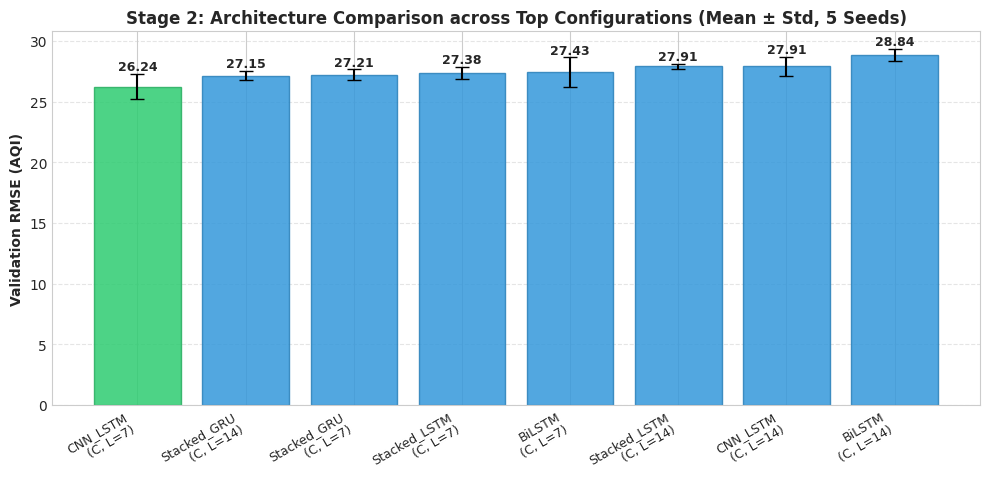

Winning Architecture: CNN_LSTM (Feature Set: C, Lookback: 7)


In [3]:
s2_df = exp_df[exp_df['stage'] == 2].copy()
s2_summary = s2_df.groupby(['model_arch', 'feature_set', 'lookback'])['val_RMSE'].agg(['mean', 'std', 'count']).reset_index()
s2_summary = s2_summary.sort_values('mean')

print("=== Stage 2: Architecture Comparison Validation RMSE (5 Seeds) ===")
display(s2_summary)

# Bar chart with error bars
fig, ax = plt.subplots(figsize=(10, 5))
x_labels = [f"{r['model_arch']}\n({r['feature_set']}, L={r['lookback']})" for _, r in s2_summary.iterrows()]
bars = ax.bar(range(len(s2_summary)), s2_summary['mean'], yerr=s2_summary['std'], capsize=5, color='#3498db', edgecolor='#2980b9', alpha=0.85)

# Highlight winner
bars[0].set_color('#2ecc71')
bars[0].set_edgecolor('#27ae60')

ax.set_xticks(range(len(s2_summary)))
ax.set_xticklabels(x_labels, rotation=30, ha='right', fontsize=9)
ax.set_ylabel('Validation RMSE (AQI)', fontsize=10, fontweight='bold')
ax.set_title('Stage 2: Architecture Comparison across Top Configurations (Mean ± Std, 5 Seeds)', fontsize=12, fontweight='bold')
ax.grid(True, linestyle='--', alpha=0.5, axis='y')

for i, (m, s) in enumerate(zip(s2_summary['mean'], s2_summary['std'])):
    ax.text(i, m + s + 0.3, f"{m:.2f}", ha='center', fontsize=9, fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_stage2_architecture_comparison.png'), dpi=300)
plt.show()

winner_s2 = s2_summary.iloc[0].to_dict()
print(f"Winning Architecture: {winner_s2['model_arch']} (Feature Set: {winner_s2['feature_set']}, Lookback: {winner_s2['lookback']})")

## 3. Stage 3: Bayesian Hyperparameter Optimization (Optuna)
Using the winning architecture from Stage 2, we execute an automated Tree-structured Parzen Estimator (TPE) study over $60$ trials. Each trial trains across $2$ fixed seeds, reporting validation loss curves to a Median Pruner to eliminate unpromising trajectories early.

Total Trials Logged: 60 (Completed: 51, Pruned: 9)

Top 5 Optuna Trials by Validation RMSE:


,number,value,params_units_l1,params_units_l2,params_learning_rate,params_dropout,params_batch_size,params_loss_fn
10,10,24.850090,80,48,0.004379,0.15,16,huber
31,31,25.129009,112,64,0.003773,0.30,16,huber
56,56,25.178444,112,48,0.003486,0.35,16,huber
33,33,25.241405,96,64,0.003995,0.35,16,huber
58,58,25.269466,112,48,0.003538,0.35,16,huber


%USERPROFILE%\AppData\Local\Temp\ipykernel_38720\2866096916.py:16: ExperimentalWarning: plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_optimization_history(study)


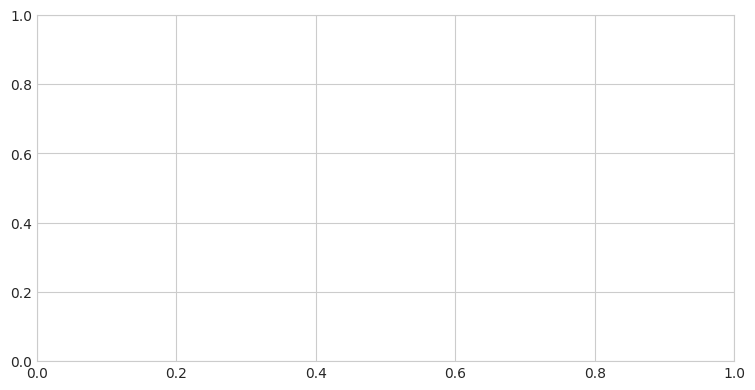

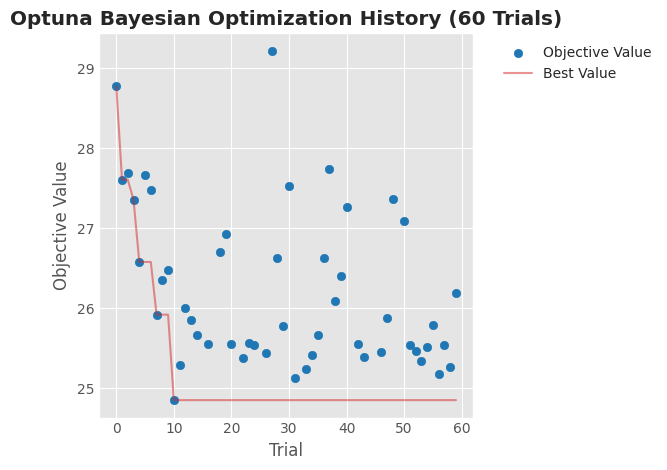

%USERPROFILE%\AppData\Local\Temp\ipykernel_38720\2866096916.py:25: ExperimentalWarning: plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ovm.plot_param_importances(study)


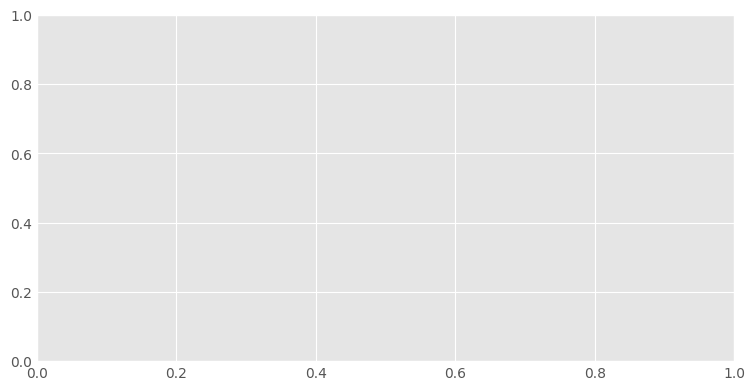

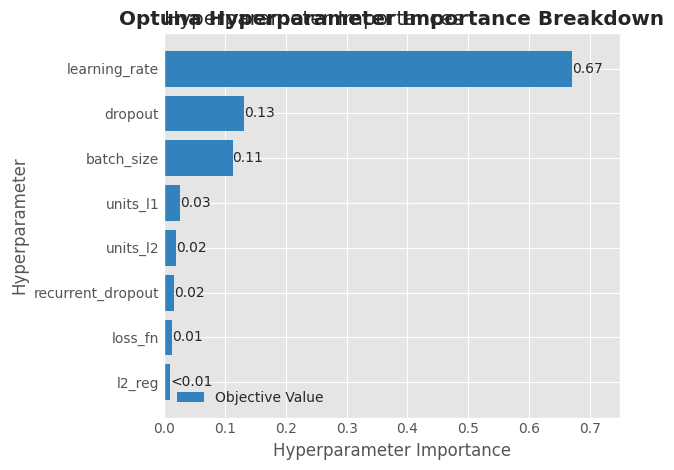


Adopted Production Deep Learning Configuration:
{
  "model_arch": "CNN_LSTM",
  "feature_set": "C",
  "lookback": 7,
  "median_epochs": 18,
  "hyperparameters": {
    "units_l1": 80,
    "units_l2": 48,
    "dropout": 0.15000000000000002,
    "recurrent_dropout": 0.2,
    "learning_rate": 0.004378795650072225,
    "batch_size": 16,
    "l2_reg": 1.113741490829352e-06,
    "loss_fn": "huber"
  },
  "seeds": [
    42,
    123,
    456,
    789,
    1011
  ]
}


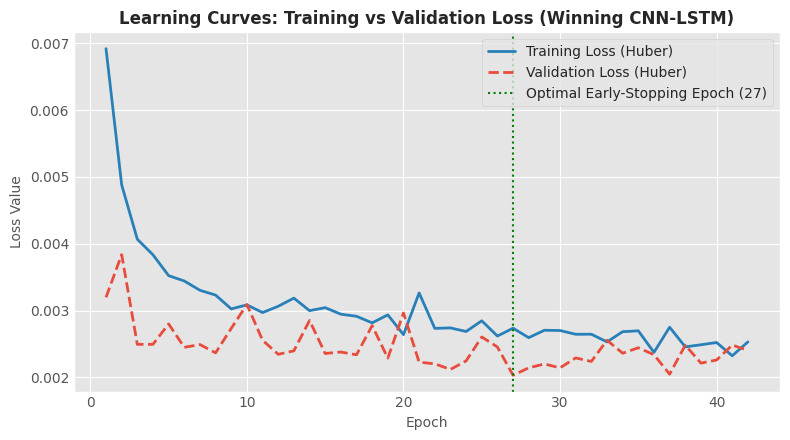

In [4]:
import optuna
import optuna.visualization.matplotlib as ovm

trials_df = pd.read_csv(os.path.join(RES_DIR, 'p6_optuna_trials.csv'))
completed_trials = trials_df[trials_df['state'] == 'COMPLETE'].sort_values('value')

print(f"Total Trials Logged: {len(trials_df)} (Completed: {len(completed_trials)}, Pruned: {(trials_df['state']=='PRUNED').sum()})")
print("\nTop 5 Optuna Trials by Validation RMSE:")
display(completed_trials[['number', 'value', 'params_units_l1', 'params_units_l2', 'params_learning_rate', 'params_dropout', 'params_batch_size', 'params_loss_fn']].head(5))

# Reload Optuna Study from DB for plotting
study = optuna.load_study(study_name="p6_optuna_hpo", storage=f"sqlite:///{os.path.join(RES_DIR, 'p6_optuna.db')}")

# Optimization history plot
fig, ax = plt.subplots(figsize=(9, 4.5))
ovm.plot_optimization_history(study)
plt.title('Optuna Bayesian Optimization History (60 Trials)', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_optuna_history.png'), dpi=300)
plt.show()

# Parameter importance plot
try:
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ovm.plot_param_importances(study)
    plt.title('Optuna Hyperparameter Importance Breakdown', fontweight='bold')
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, 'p6_optuna_importance.png'), dpi=300)
    plt.show()
except Exception as e:
    print("Parameter importance plot notice:", e)

# Load final config
with open(os.path.join(MODELS_DIR, 'dl_config.json'), 'r') as f:
    dl_config = json.load(f)

print("\nAdopted Production Deep Learning Configuration:")
print(json.dumps(dl_config, indent=2))

# Plot Learning Curves for Final Configuration
import tensorflow as tf
from src.sequences import load_scaled_dataset, make_sequences_1day
from src.models_dl import build_model

df_seq, sc_tgt, _, _ = load_scaled_dataset(data_path=os.path.join(DATA_PROCESSED, 'chennai_clean_full.csv'), models_dir=MODELS_DIR)
p = dl_config['hyperparameters']
seqs = make_sequences_1day(df_seq, feature_set=dl_config['feature_set'], lookback=dl_config['lookback'])
X_tr, y_tr = seqs['train']['X'], seqs['train']['y']
X_val, y_val = seqs['val']['X'], seqs['val']['y']

m_lc = build_model(
    dl_config['model_arch'], input_shape=(dl_config['lookback'], X_tr.shape[2]),
    units_l1=p['units_l1'], units_l2=p['units_l2'], dropout=p['dropout'],
    recurrent_dropout=p['recurrent_dropout'], l2_reg=p['l2_reg'],
    output_dim=1, lr=p['learning_rate'], loss_fn=p['loss_fn']
)
es_lc = tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True)
hist_lc = m_lc.fit(X_tr, y_tr, validation_data=(X_val, y_val), epochs=50, batch_size=p['batch_size'], callbacks=[es_lc], verbose=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(range(1, len(hist_lc.history['loss'])+1), hist_lc.history['loss'], color='#2980b9', lw=2, label='Training Loss (Huber)')
ax.plot(range(1, len(hist_lc.history['val_loss'])+1), hist_lc.history['val_loss'], color='#e74c3c', lw=2, linestyle='--', label='Validation Loss (Huber)')
best_ep_idx = int(np.argmin(hist_lc.history['val_loss']) + 1)
ax.axvline(best_ep_idx, color='green', linestyle=':', label=f'Optimal Early-Stopping Epoch ({best_ep_idx})')
ax.set_title('Learning Curves: Training vs Validation Loss (Winning CNN-LSTM)', fontsize=12, fontweight='bold')
ax.set_xlabel('Epoch', fontsize=10)
ax.set_ylabel('Loss Value', fontsize=10)
ax.legend(frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_learning_curves.png'), dpi=300)
plt.show()

## 4. Final 1-Day Model: Ensemble Evaluation & MC Dropout Uncertainty
The production model is retrained on the combined **Train + Validation** partition (`2016-01-01` to `2019-08-31`, $1,339$ days) for the median optimal epoch count across $5$ random seeds. The 5-seed ensemble average represents "the LSTM" in all benchmark comparisons.

Uncertainty estimation is achieved via **Monte Carlo (MC) Dropout**: $100$ stochastic forward passes per seed ($500$ passes total) are executed at test inference time with dropout enabled, constructing an empirical $95\%$ predictive confidence interval.

Test Set 1-Day LSTM Performance (N=182 Days):
 - Empirical 95% PI Coverage: 37.91%
 - Mean 95% Interval Width:    31.69 AQI units


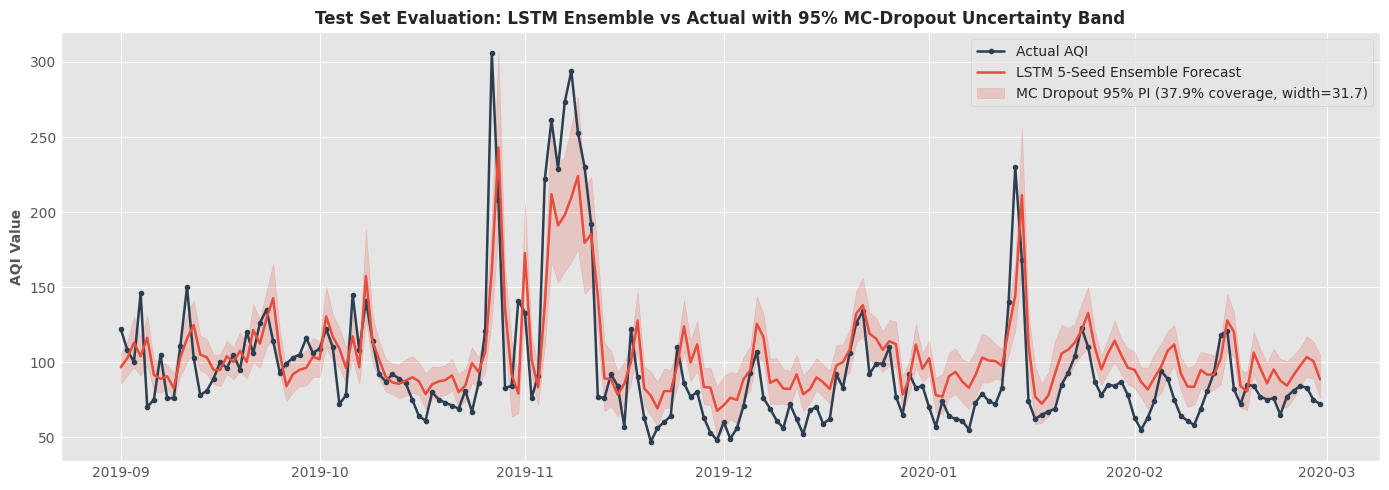

In [5]:
p6_preds = pd.read_csv(os.path.join(RES_DIR, 'p6_predictions.csv'))
p6_preds['date'] = pd.to_datetime(p6_preds['date'])

# Extract test set predictions for LSTM
test_lstm = p6_preds[(p6_preds['model'] == 'LSTM') & (p6_preds['split'] == 'test')].sort_values('date')

# Compute empirical coverage and width
test_actual = test_lstm['actual'].values
test_pred = test_lstm['predicted'].values
pi_low = test_lstm['pi_lower_95'].values
pi_upp = test_lstm['pi_upper_95'].values

coverage = np.mean((test_actual >= pi_low) & (test_actual <= pi_upp)) * 100.0
mean_width = np.mean(pi_upp - pi_low)

print(f"Test Set 1-Day LSTM Performance (N={len(test_lstm)} Days):")
print(f" - Empirical 95% PI Coverage: {coverage:.2f}%")
print(f" - Mean 95% Interval Width:    {mean_width:.2f} AQI units")

# Plot Test Actual vs Predicted with MC Dropout Band
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(test_lstm['date'], test_actual, color='#2c3e50', lw=1.8, marker='o', markersize=3, label='Actual AQI')
ax.plot(test_lstm['date'], test_pred, color='#e74c3c', lw=1.8, label='LSTM 5-Seed Ensemble Forecast')
ax.fill_between(test_lstm['date'], pi_low, pi_upp, color='#e74c3c', alpha=0.2, label=f'MC Dropout 95% PI ({coverage:.1f}% coverage, width={mean_width:.1f})')
ax.set_title('Test Set Evaluation: LSTM Ensemble vs Actual with 95% MC-Dropout Uncertainty Band', fontsize=12, fontweight='bold')
ax.set_ylabel('AQI Value', fontsize=10, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_test_actual_vs_predicted.png'), dpi=300)
plt.show()

## 5. Direct Multi-Step Horizon Evaluation (1 to 7 Days Ahead)
We evaluate the direct 7-day multi-step model (`Dense(7)`) across horizons $h=1..7$ on the exact same $175$ forecast origins established in Phase 5 (`p5_multistep_origins.csv`), comparing directly against `ARIMA-Fourier (multi-step)` and `Persistence`.

=== Multi-Step Forecast Performance (RMSE by Horizon 1..7, N=175 Origins) ===


model,Persistence,ARIMA-Fourier (multi-step),LSTM-7day
horizon,,,
1,32.103,32.251,43.610
2,NaN,42.829,48.016
3,NaN,46.045,52.019
4,NaN,47.827,53.111
5,NaN,49.329,54.734
6,NaN,50.057,52.435
7,60.607,50.352,51.884


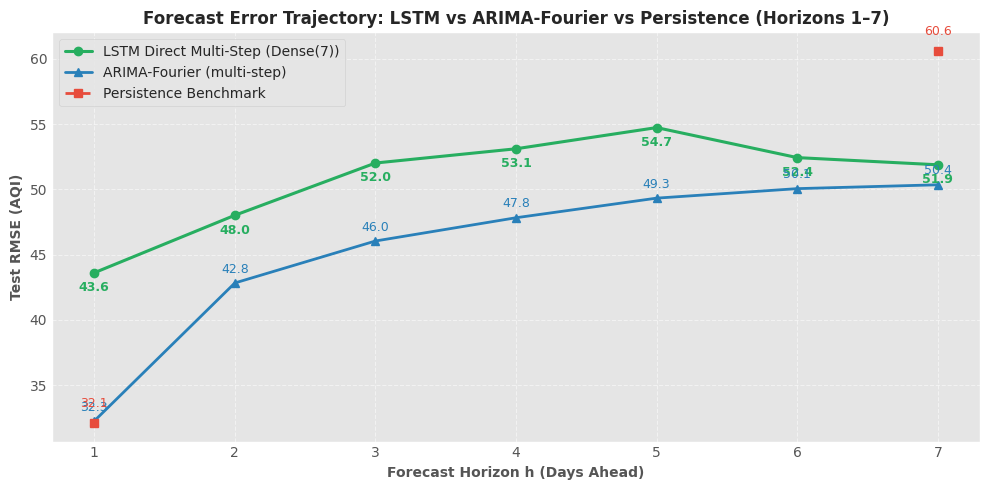

In [6]:
p6_metrics = pd.read_csv(os.path.join(RES_DIR, 'p6_metrics.csv'))

# Filter multi-step test models
ms_models = ['Persistence', 'ARIMA-Fourier (multi-step)', 'LSTM-7day']
ms_df = p6_metrics[(p6_metrics['split'] == 'test') & (p6_metrics['model'].isin(ms_models)) & (p6_metrics['horizon'] <= 7)].copy()

print("=== Multi-Step Forecast Performance (RMSE by Horizon 1..7, N=175 Origins) ===")
piv_rmse = ms_df.pivot(index='horizon', columns='model', values='RMSE')[['Persistence', 'ARIMA-Fourier (multi-step)', 'LSTM-7day']]
display(piv_rmse)

# Plot RMSE vs Horizon
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(piv_rmse.index, piv_rmse['LSTM-7day'], marker='o', lw=2.2, color='#27ae60', label='LSTM Direct Multi-Step (Dense(7))')
ax.plot(piv_rmse.index, piv_rmse['ARIMA-Fourier (multi-step)'], marker='^', lw=2.0, color='#2980b9', label='ARIMA-Fourier (multi-step)')
ax.plot(piv_rmse.index, piv_rmse['Persistence'], marker='s', lw=2.0, color='#e74c3c', linestyle='--', label='Persistence Benchmark')

ax.set_title('Forecast Error Trajectory: LSTM vs ARIMA-Fourier vs Persistence (Horizons 1–7)', fontsize=12, fontweight='bold')
ax.set_xlabel('Forecast Horizon h (Days Ahead)', fontsize=10, fontweight='bold')
ax.set_ylabel('Test RMSE (AQI)', fontsize=10, fontweight='bold')
ax.set_xticks(range(1, 8))
ax.grid(True, linestyle='--', alpha=0.5)
ax.legend(frameon=True)

for h in range(1, 8):
    l_val = piv_rmse.loc[h, 'LSTM-7day']
    a_val = piv_rmse.loc[h, 'ARIMA-Fourier (multi-step)']
    p_val = piv_rmse.loc[h, 'Persistence']
    ax.annotate(f"{l_val:.1f}", (h, l_val - 1.4), ha='center', fontsize=9, color='#27ae60', fontweight='bold')
    ax.annotate(f"{a_val:.1f}", (h, a_val + 0.8), ha='center', fontsize=9, color='#2980b9')
    ax.annotate(f"{p_val:.1f}", (h, p_val + 1.2), ha='center', fontsize=9, color='#e74c3c')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_rmse_vs_horizon.png'), dpi=300)
plt.show()

## 6. Hybrid ARIMAX + LSTM & Lockdown Stress-Testing
We inspect the **Hybrid ARIMAX + LSTM** architecture, which models ARIMAX residuals using past residual history and auxiliary environmental features.

We then subject all candidate forecasting paradigms to the **COVID-19 Lockdown Stress Window** (`2020-03-01` to `2020-06-30`, $122$ days) without parameter retraining to diagnose structural breakdown.

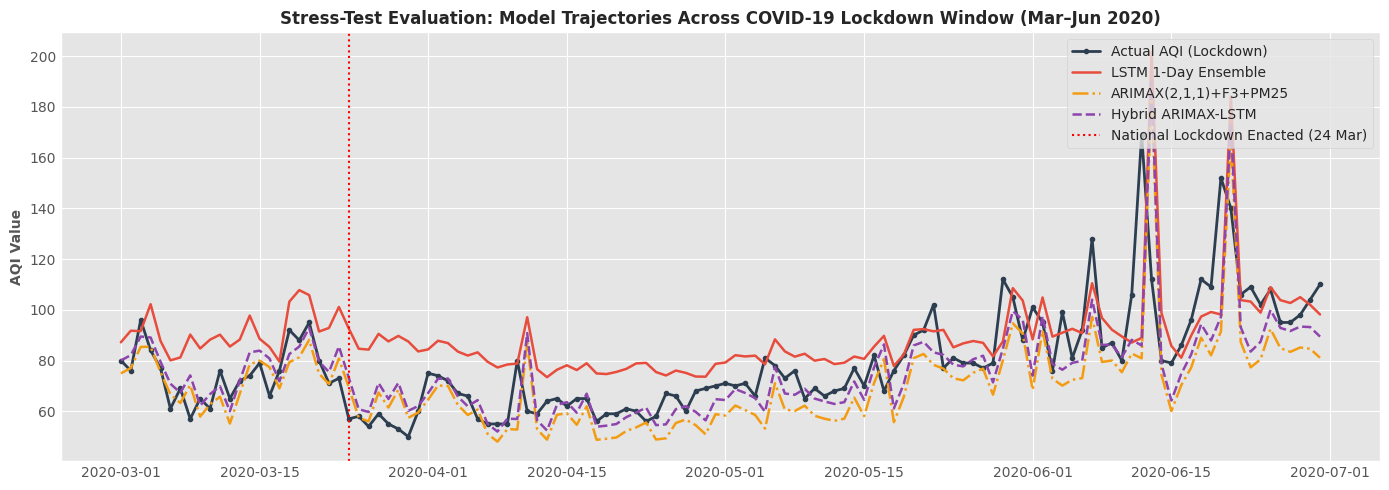

=== Stress-Test Performance Comparison (Lockdown Mar–Jun 2020) ===


,model,RMSE,MAE,R2,QWK
12,Persistence,14.455,9.410,0.4928,0.5390
13,7-Day MA,14.646,10.225,0.4793,0.4882
38,Hybrid ARIMAX-LSTM,15.617,9.458,0.4080,0.2440
27,"Final_ARIMAX(2,1,1)+F3+PM25",17.740,12.368,0.2361,0.1835
29,LSTM,20.278,15.405,0.0019,0.3661
14,Seasonal Naive (365d),37.925,28.820,-2.4913,0.1625


In [7]:
# Extract stress test predictions
stress_preds = p6_preds[p6_preds['split'] == 'stress'].copy()

# Plot Stress Actual vs Predicted across paradigms
stress_lstm = stress_preds[stress_preds['model'] == 'LSTM'].sort_values('date')
stress_hyb = stress_preds[stress_preds['model'] == 'Hybrid ARIMAX-LSTM'].sort_values('date')

# Load Phase 5 stress predictions for ARIMAX
p5_preds = pd.read_csv(os.path.join(RES_DIR, 'p5_predictions.csv'))
p5_preds['date'] = pd.to_datetime(p5_preds['date'])
stress_arimax = p5_preds[(p5_preds['model']=='Final_ARIMAX(2,1,1)+F3+PM25') & (p5_preds['split']=='stress')].sort_values('date')

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(stress_lstm['date'], stress_lstm['actual'], color='#2c3e50', lw=2.0, marker='o', markersize=3, label='Actual AQI (Lockdown)')
ax.plot(stress_lstm['date'], stress_lstm['predicted'], color='#e74c3c', lw=1.8, label='LSTM 1-Day Ensemble')
ax.plot(stress_arimax['date'], stress_arimax['predicted'], color='#f39c12', lw=1.8, linestyle='-.', label='ARIMAX(2,1,1)+F3+PM25')
ax.plot(stress_hyb['date'], stress_hyb['predicted'], color='#8e44ad', lw=1.8, linestyle='--', label='Hybrid ARIMAX-LSTM')

ax.axvline(pd.Timestamp('2020-03-24'), color='red', linestyle=':', lw=1.5, label='National Lockdown Enacted (24 Mar)')
ax.set_title('Stress-Test Evaluation: Model Trajectories Across COVID-19 Lockdown Window (Mar–Jun 2020)', fontsize=12, fontweight='bold')
ax.set_ylabel('AQI Value', fontsize=10, fontweight='bold')
ax.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_stress_actual_vs_predicted.png'), dpi=300)
plt.show()

# Comparative Stress Table
stress_metrics_table = p6_metrics[(p6_metrics['split'] == 'stress') & (p6_metrics['horizon'] == 1)][['model', 'RMSE', 'MAE', 'R2', 'QWK']].copy()
print("=== Stress-Test Performance Comparison (Lockdown Mar–Jun 2020) ===")
display(stress_metrics_table.sort_values('RMSE'))

## 7. Operational Health Classification & Confusion Matrix
To evaluate operational decision support for refinery managers, we assess classification accuracy and Quadratic Weighted Kappa (QWK) across official CPCB categories on the test set.

Operational Health Category Metrics (Test Set):
 - Classification Accuracy: 68.68%
 - Quadratic Weighted Kappa: 0.5384
 - Macro F1-Score:           0.3167


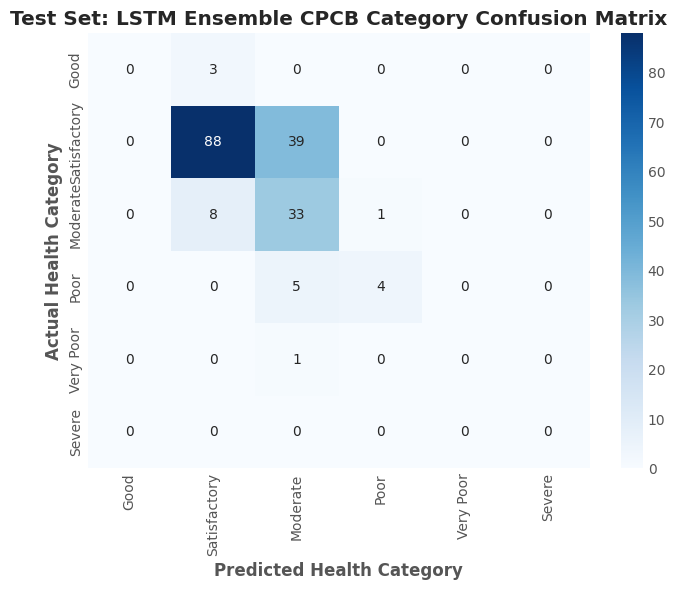

In [8]:
from src.metrics import compute_category_metrics, CPCB_CATEGORIES

cat_res = compute_category_metrics(test_actual, test_pred)
cm = cat_res['Confusion_Matrix']

print(f"Operational Health Category Metrics (Test Set):")
print(f" - Classification Accuracy: {cat_res['Accuracy']*100:.2f}%")
print(f" - Quadratic Weighted Kappa: {cat_res['QWK']:.4f}")
print(f" - Macro F1-Score:           {cat_res['Macro_F1']:.4f}")

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CPCB_CATEGORIES, yticklabels=CPCB_CATEGORIES, ax=ax)
ax.set_title('Test Set: LSTM Ensemble CPCB Category Confusion Matrix', fontweight='bold')
ax.set_xlabel('Predicted Health Category', fontweight='bold')
ax.set_ylabel('Actual Health Category', fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'p6_confusion_matrix.png'), dpi=300)
plt.show()

## 8. Consolidated Performance Table across All Paradigms
We consolidate the performance metrics across all evaluated models on the out-of-sample Test set ($1$-Day Ahead).

In [9]:
# Consolidated 1-Day Test Table
test_1d = p6_metrics[(p6_metrics['split'] == 'test') & (p6_metrics['horizon'] == 1)][['model', 'RMSE', 'MAE', 'MAPE', 'R2', 'QWK', 'Accuracy']].copy()
test_1d = test_1d.drop_duplicates(subset=['model']).sort_values('RMSE')

print("=== Consolidated 1-Day Ahead Test Set Benchmark ===")
display(test_1d)

=== Consolidated 1-Day Ahead Test Set Benchmark ===


,model,RMSE,MAE,MAPE,R2,QWK,Accuracy
26,"Final_ARIMAX(2,1,1)+F3+PM25",25.965,18.447,20.25,0.6657,0.6471,0.7692
37,Hybrid ARIMAX-LSTM,26.814,19.913,22.58,0.6435,0.6296,0.7473
28,LSTM,27.633,21.211,23.92,0.6214,0.5384,0.6868
6,Persistence,32.103,19.555,19.40,0.4889,0.5951,0.7363
18,ARIMA-Fourier (multi-step),32.251,22.365,25.10,0.5005,0.5555,0.7257
7,7-Day MA,42.443,26.491,27.19,0.1067,0.3405,0.6484
30,LSTM-7day,43.610,34.232,40.88,0.0867,0.0107,0.2800
8,Seasonal Naive (365d),71.605,53.863,61.80,-1.5426,-0.0554,0.3681
